# Dog breed - Image Classification - ResNet 50

This notebook lists all the steps that you need to complete the complete this project. You will need to complete all the TODOs in this notebook as well as in the README and the two python scripts included with the starter code.


### Overview

The goal of this project is to build Computer Vision model to classify breed of the dogs on provided images. In order to achieve this goal pre-train3e ResNet50 model is employed and then fine-tuned on Dog Breed dataset. AWS Sagemaker is utilized to train and host model for inference.

In [1]:
import sagemaker
import boto3
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## Dataset

**Dog breed** dataset was utilized to build *Deep Learning* model. It is split into 3 subsets: *train* (6680 images), *validation* (835 images) and *test* (836 images) and contains 133 dog breeds. Images are not standarized and they have difference sizes.

In order to use this dataset, we need to upload it to S3 bucket, so it can used available in SageMaker container. First we need to download zip file, then we need to unzip it and upload all images to S3 bucket.

In [3]:
# Command to download and unzip data
!wget https://s3-us-west-1.amazonaws.com/udacity-aind/dog-project/dogImages.zip
!unzip dogImages.zip

--2026-11-07 08:40:00--  https://s3-us-west-1.amazonaws.com/udacity-aind/dog-project/dogImages.zip
Resolving s3-us-west-1.amazonaws.com (s3-us-west-1.amazonaws.com)... 16.15.0.167, 16.15.0.174, 16.15.1.255, ...
Connecting to s3-us-west-1.amazonaws.com (s3-us-west-1.amazonaws.com)|16.15.0.167|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1132023110 (1.1G) [application/zip]
Saving to: ‘dogImages.zip’

dogImages.zip       100%[===================>]   1.05G  40.6MB/s    in 31s     

2026-11-07 08:40:31 (35.2 MB/s) - ‘dogImages.zip’ saved [1132023110/1132023110]

Archive:  dogImages.zip
   creating: dogImages/
   creating: dogImages/test/
   creating: dogImages/train/
   creating: dogImages/valid/
   creating: dogImages/test/001.Affenpinscher/
  inflating: dogImages/test/001.Affenpinscher/Affenpinscher_00003.jpg  
  inflating: dogImages/test/001.Affenpinscher/Affenpinscher_00023.jpg  
  inflating: dogImages/test/001.Affenpinscher/Affenpinscher_00036.jpg  
  infla

### Images distribution per classes

Let's see what are dog breeds we are going to classify, and how many samples per class we have:

In [6]:
dataset_root_path = Path('dogImages')
subsets = ['train', 'test', 'valid']
breeds = dict()

# Iterate over files and count images per dog breed and subset
for subset in subsets:
    subset_path = dataset_root_path / subset
    for dog_breed_folder in os.listdir(subset_path):
        path = subset_path / dog_breed_folder
        if not os.path.isdir(path):
            continue
        
        breed_name = dog_breed_folder.split('.')[1].replace('_', ' ')
        records = breeds.get(breed_name, [])
        images = [file for file in os.listdir(path) if not os.path.isdir((path / file))]
        records.append(len(images))
        breeds[breed_name] = records

In [18]:
breeds_as_list = [
    (breed_name, *breed_values)
    for breed_name, breed_values in breeds.items()
]

breed_df = pd.DataFrame(
    breeds_as_list,
    columns=['breed', 'train', 'test', 'valid']
)
breed_df.head()

,breed,train,test,valid
0,Affenpinscher,64,8,8
1,Afghan hound,58,8,7
2,Airedale terrier,52,6,7
3,Akita,63,8,8
4,Alaskan malamute,77,10,9


Let's plot that distribution:

In [55]:
breed_df = breed_df.set_index('breed')

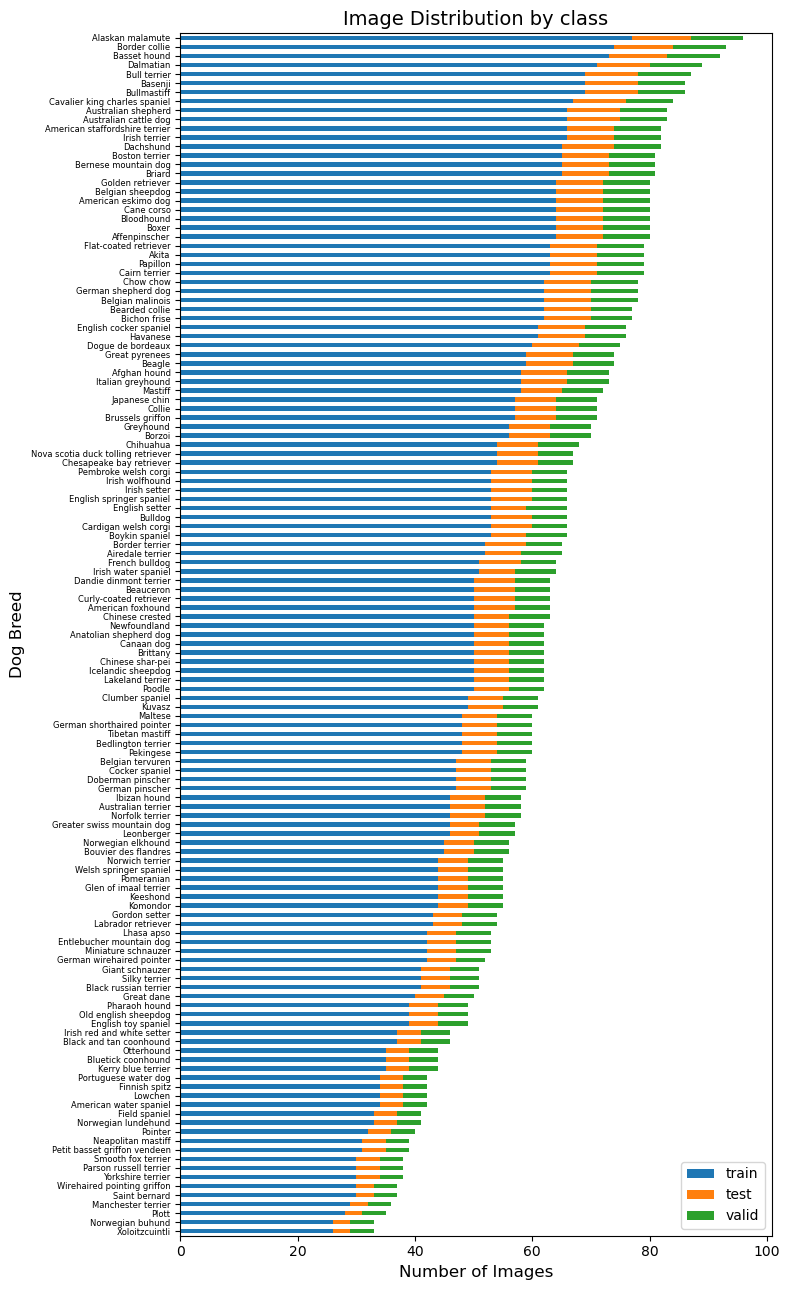

In [61]:
breed_df = breed_df.loc[
    breed_df[["train", "valid", "test"]]
    .sum(axis=1)
    .sort_values(ascending=True)
    .index
]
ax = breed_df.plot(
    kind="barh",
    stacked=True,
    figsize=(8, 13)
)
ax.set_title("Image Distribution by class", fontsize=14)
ax.set_ylabel("Dog Breed", fontsize=12)
ax.set_xlabel("Number of Images", fontsize=12)
ax.tick_params(axis="y", labelsize=6)
plt.tight_layout()
plt.show()

We can see that number of images per dog breed is not evenly distributed. For **Alaskan malamute** we have almost 100 images (in total), while for **Xoloitzcunictli** we have around 35 pictures. Proportions between train, test and valid subsets seem to be the same.

Let's see how many records we have per dataset:

In [64]:
breed_df[['train', 'valid', 'test']].sum(axis=0)

train    6680
valid     835
test      836
dtype: int64

Let's counts breeds we are going to deal with:

In [75]:
breed_df.count()

train    133
test     133
valid    133
dtype: int64

### Size of images

Let's also see what is the size of images:

In [65]:
from PIL import Image

def get_image_size(path):
    with Image.open(path) as img:
        return(img.width, img.height)

In [67]:
image_sizes = []

# Iterate over all images and extract images size
for subset in subsets:
    subset_path = dataset_root_path / subset
    for dog_breed_folder in os.listdir(subset_path):
        path = subset_path / dog_breed_folder
        if not os.path.isdir(path):
            continue

        images = [get_image_size(path / file) for file in os.listdir(path) if not os.path.isdir((path / file))]
        image_sizes.extend(images)

In [70]:
image_size_df = pd.DataFrame(
    image_sizes,
    columns=['width', 'height']
)
image_size_df.head()

,width,height
0,400,300
1,480,360
2,321,316
3,500,375
4,360,270


In [71]:
image_size_df.describe()

,width,height
count,8351.000000,8351.000000
mean,567.032571,529.044905
std,389.006647,333.197594
min,105.000000,113.000000
25%,375.000000,360.000000
50%,500.000000,467.000000
75%,640.000000,600.000000
max,4278.000000,4003.000000


We can see that size of images is quite diverse:
* mean of *width* is 567 pixels while median is 500, min is 105 and max is 4278
* mean of *height* is 529 pixels while median is 467, min is 113 and max is 4003

We will need to scale images to the same sizes, so model can properly use all images.

### Upload dataset to S3

In [20]:
import sagemaker
from sagemaker.core.helper.session_helper import Session

bucket = Session().default_bucket()

os.environ["S3_BUCKET"] = bucket
!aws s3 sync ./dogImages/train s3://${S3_BUCKET}/dataset/train/
!aws s3 sync ./dogImages/test s3://${S3_BUCKET}/dataset/test/
!aws s3 sync ./dogImages/valid s3://${S3_BUCKET}/dataset/valid/

upload: dogImages/train/001.Affenpinscher/Affenpinscher_00001.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00001.jpg
upload: dogImages/train/001.Affenpinscher/Affenpinscher_00002.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00002.jpg
upload: dogImages/train/001.Affenpinscher/Affenpinscher_00004.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00004.jpg
upload: dogImages/train/001.Affenpinscher/Affenpinscher_00006.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00006.jpg
upload: dogImages/train/001.Affenpinscher/Affenpinscher_00005.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00005.jpg
upload: dogImages/train/001.Affenpinscher/Affenpinscher_00007.jpg to s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/train/001.Affenpinscher/Affenpinscher_00007.jpg
upload: dogImages/trai

Removing problematic image:

In [ ]:
!aws s3 rm s3://${S3_BUCKET}/dataset/train/098.Leonberger/Leonberger_06571.jpg

## Hyperparameter Tuning

**Resnet50** was utilized to build classification model. As part of this section we are going to fine-tune pre-trained model. We will perform optimization for following hyperparamters:

| Hyperparameter | Search Space         |
| -------------- | -------------------- |
| Batch Size     | [64, 128, 256, 512]  |
| Epochs         | [1, 2, 3, 4, 5]      |
| Learning rate  | 0.001 - 0.01         |
| Optimizer      | [Adam, SGD, RMSprop] |


Please see `hpo.py` as it contains script to perform training procedure with PyTorch.

Extract S3 bucket, AWS region, and IAM execution role ARN:

In [2]:
import sagemaker
from sagemaker.core.helper.session_helper import Session, get_execution_role

bucket = Session().default_bucket()
region = Session().boto_region_name
role = get_execution_role()

Get image for PyTorch 2.6, Python 3.12 and specified instance type:

In [3]:
from sagemaker.core import image_uris

training_image = image_uris.retrieve(
    framework="pytorch",
    region=region,
    version="2.6",
    py_version="py312",
    instance_type="ml.g4dn.xlarge",
    image_scope="training",
)

Define training details:
* source code
* compute
* stopping conditions

In [4]:
# [1] https://sagemaker.readthedocs.io/en/v3.6.0/v3-examples/ml-ops-examples/v3-hyperparameter-tuning-example/v3-hyperparameter-tuning-example.html

from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, OutputDataConfig, SourceCode, StoppingCondition

source_code = SourceCode(
    source_dir=".",
    entry_script="hpo.py"
)
compute = Compute(
    instance_type="ml.g4dn.xlarge",
    instance_count=1
)
stopping_condition = StoppingCondition(
    max_runtime_in_seconds=3600
)

model_trainer = ModelTrainer(
    training_image=training_image,
    source_code=source_code,
    role=role,
    compute=compute,
    stopping_condition=stopping_condition,
    base_job_name='resnet50-dog-breed',
    hyperparameters={
        'num-classes': 133
    }
)

Now, define details of hyperparamaters of optimization:

In [5]:
from sagemaker.train.tuner import HyperparameterTuner
from sagemaker.core.parameter import ContinuousParameter, CategoricalParameter

hyperparameter = {
    'lr': ContinuousParameter(0.001, 0.01),
    'batch-size': CategoricalParameter([64, 128, 256, 512]),
    'epochs': CategoricalParameter([1, 2, 3, 4, 5]),
    'optimizer': CategoricalParameter(['adam', 'sgd', 'rmsprop'])
}

metric_definitions = [
    {
        "Name": "train:loss",
        "Regex": r"Train Avg Loss: ([-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?)"
    },
    {
        "Name": "train:accuracy",
        "Regex": r"Train Accuracy: ([0-9]*\.?[0-9]+)"
    },
    {
        "Name": "validation:loss",
        "Regex": r"Validation Avg Loss: ([-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?)"
    },
    {
        "Name": "validation:accuracy",
        "Regex": r"Validation Accuracy: ([0-9]*\.?[0-9]+)"
    },
    {
        "Name": "test:loss",
        "Regex": r"Test Avg Loss: ([-+]?[0-9]*\.?[0-9]+(?:[eE][-+]?[0-9]+)?)"
    },
        {
        "Name": "test:accuracy",
        "Regex": r"Test Accuracy: ([0-9]*\.?[0-9]+)"
    }
]

tuner = HyperparameterTuner(
    model_trainer=model_trainer,
    objective_metric_name='validation:loss',
    hyperparameter_ranges=hyperparameter,
    metric_definitions=metric_definitions,
    max_jobs=5,
    max_parallel_jobs=1,
    strategy="Random",
    objective_type="Minimize",
    early_stopping_type="Auto"
)

and run process for dataset stored in S3 Bucket:

In [34]:
from sagemaker.train.configs import InputData

model_inputs = [
    InputData(
        channel_name="train", 
        data_source=f"s3://{bucket}/dataset/train/",
        content_type="application/x-image"
    ),
    InputData(
        channel_name="validation", 
        data_source=f"s3://{bucket}/dataset/valid/",
        content_type="application/x-image"
    ),
    InputData(
        channel_name="test", 
        data_source=f"s3://{bucket}/dataset/test/",
        content_type="application/x-image"
    )
]

tuner.tune(
    inputs=model_inputs,
    wait=True
)

Output()

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



### Hyperparameters optimization results
We obtained below results:

| Batch Size | Epochs | Learning Rate             | Optimizer | Loss value             |
| ---------- | ------ | ------------------------- | --------- | ---------------------- |
|     **64** |  **4** | **0.0038940075053948960** |  **Adam** | **0.4791969954967499** |
|         64 |      4 |     0.0046897104564080050 |      Adam |     0.6021945476531982 |
|         64 |      1 |     0.0037338008076578787 |   RMSprop |     0.7474458813667297 |
|        256 |      3 |     0.0015819044035065258 |   RMSprop |     1.6783027648925781 |
|         64 |      3 |     0.0097900668677548120 |       SGD |     2.8632850646972656 |

In [35]:
best_job_name = tuner.best_training_job()
print(f"Best Training Job: {best_job_name}")

Best Training Job: pytorch-training-261107-1928-001-862e23dd


In [40]:
tuner.describe().best_training_job.tuned_hyper_parameters

{'batch-size': '64',
 'epochs': '4',
 'lr': '0.003894007505394896',
 'optimizer': 'adam'}

In [50]:
tuner.describe().best_training_job.final_hyper_parameter_tuning_job_objective_metric

FinalHyperParameterTuningJobObjectiveMetric(metric_name='validation:loss', value=0.4791969954967499, type=Unassigned())

In [57]:
sm = boto3.client("sagemaker")

response = sm.list_training_jobs_for_hyper_parameter_tuning_job(
    HyperParameterTuningJobName=tuner.describe().hyper_parameter_tuning_job_name,
    SortBy="FinalObjectiveMetricValue",
    SortOrder="Ascending"
)

for job in response["TrainingJobSummaries"]:
    print(job["TrainingJobName"], job["TunedHyperParameters"], job['FinalHyperParameterTuningJobObjectiveMetric']['Value'])


pytorch-training-261107-1928-001-862e23dd {'batch-size': '64', 'epochs': '4', 'lr': '0.003894007505394896', 'optimizer': 'adam'} 0.4791969954967499
pytorch-training-261107-1928-003-b0536e77 {'batch-size': '64', 'epochs': '4', 'lr': '0.004689710456408005', 'optimizer': 'adam'} 0.6021945476531982
pytorch-training-261107-1928-004-9d5c7154 {'batch-size': '64', 'epochs': '1', 'lr': '0.0037338008076578787', 'optimizer': 'rmsprop'} 0.7474458813667297
pytorch-training-261107-1928-005-e0c5db23 {'batch-size': '256', 'epochs': '3', 'lr': '0.0015819044035065258', 'optimizer': 'rmsprop'} 1.6783027648925781
pytorch-training-261107-1928-002-1af0fd29 {'batch-size': '64', 'epochs': '3', 'lr': '0.009790066867754812', 'optimizer': 'sgd'} 2.8632850646972656


## Model Profiling and Debugging

Now, we are using the best configuration to train **ResNet50** again with the best found configuration:

| Hyperparamter | Value                |
| ------------- | -------------------- |
| Batch size    |                   64 |
| Epochs        |                    4 |
| Learning rate | 0.003894007505394896 | 
| Optimizer     |                 Adam |

Since Amazon SageMaker Profiler is planned to not longer be supported [1] and AWS SageMaker Debug is no longer available [2], I decided to employ TensorBoard and CloudWatch as replacement:
- CloudWatch metrics as replacement for Amazon SageMaker Profiler
- TensorBoard as replacement for AWS SageMaker Debug

[1] https://docs.aws.amazon.com/sagemaker/latest/dg/profiler-availability-change.html  
[2] https://docs.aws.amazon.com/sagemaker/latest/dg/debugger-availability-change.html

First, we need to prepare our training job. See `train_model.py` for script run in container:

In [4]:
import os

from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, OutputDataConfig, SourceCode, StoppingCondition
from sagemaker.core.debugger import TensorBoardOutputConfig

source_code = SourceCode(
    source_dir=".",
    entry_script="train_model.py"
)
compute = Compute(
    instance_type="ml.g4dn.xlarge",
    instance_count=1
)
stopping_condition = StoppingCondition(
    max_runtime_in_seconds=3600
)

model_trainer = ModelTrainer(
    training_image=training_image,
    source_code=source_code,
    role=role,
    compute=compute,
    stopping_condition=stopping_condition,
    base_job_name='resnet50-dog-breed',
    hyperparameters={
        'num-classes': 133,
        'batch-size': '64',
        'epochs': '4',
        'lr': '0.003894007505394896',
        'optimizer': 'adam'
    }
)

In [5]:
from sagemaker.train.configs import InputData

model_inputs = [
    InputData(
        channel_name="train", 
        data_source=f"s3://{bucket}/dataset/train/",
        content_type="application/x-image"
    ),
    InputData(
        channel_name="validation", 
        data_source=f"s3://{bucket}/dataset/valid/",
        content_type="application/x-image"
    ),
    InputData(
        channel_name="test", 
        data_source=f"s3://{bucket}/dataset/test/",
        content_type="application/x-image"
    )
]

model_trainer.train(input_data_config=model_inputs)

Output()

### Metrics output

![Tensorboard](./assets/tensorboard_plots.png)

On above plot we can se how loss value and accuracy have been changing over 419 steps (one step represents one training loop of single batch). We can see that in both cases (accuracy and loss) converge. It doesn't change much after 300 steps. It may suggests that current configuration (model, hyperparameters) doesn't allow to significantly improve performance.

### CloudWatch metrics

![CloudWatch](./assets/cloudwatch_metrics.png)

On above chart we can see utilization of hardware resource (like CPU, GPU, memory, disk) during training. It looks like CPU is the resource that is utilized the most. Rest of resources is utilized on quite low level. It indicates that in terms of performance this machine should be able to handle much more complicated tasks. The fact that GPU is utilized all the time indicates that GPU was indeed used to fine tune this model.

## Model Deploying

Let's create endpoint, so we can use endpoint. Because we are using *Script mode* we need to define custom recipe how to get response from model. This recipe can be found in `deploy/inference.py` file.

In [28]:
from sagemaker.core.helper.session_helper import Session
from sagemaker.serve import ModelBuilder
from sagemaker.serve.mode.function_pointers import Mode
from sagemaker.serve.utils.types import ModelServer
from sagemaker.train.configs import SourceCode
from sagemaker.core import image_uris

# Get image ARN for inference
INFERENCE_IMAGE_URI = image_uris.retrieve(
    framework="pytorch",
    region=region,
    version="2.6.0",
    py_version="py312",
    instance_type="ml.m5.xlarge",
    image_scope="inference",
)

# Get model location in S3 bucket
model_artifact_s3_uri = model_trainer._latest_training_job.model_artifacts.s3_model_artifacts

inference_source_code = SourceCode(
    source_dir="./deploy",
    entry_script="inference.py",
)

model_builder = ModelBuilder(
    image_uri=INFERENCE_IMAGE_URI,
    model_server=ModelServer.TORCHSERVE,
    source_code=inference_source_code,
    s3_model_data_url=model_artifact_s3_uri,
    instance_type="ml.g4dn.xlarge",
    sagemaker_session=Session(),
    role_arn=role,
)

model_builder.build(model_name="resnet50-dog-breed", mode=Mode.SAGEMAKER_ENDPOINT)

endpoint = model_builder.deploy(
    endpoint_name="resnet50-dog-breed-endpoint",
    initial_instance_count=1,
)

DEBUG:sagemaker.core.utils.utils:No ModelMetadata provided. ModelBuilder is not handling MLflow model input
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::XXXXXXXXXXXX:role/service-role/AmazonSageMaker-ExecutionRole-20261107T093182' (access denied); permission verdict unknown.
INFO:sagemaker.core.helper.iam_role_resolver:Cannot simulate policies for 'arn:aws:iam::XXXXXXXXXXXX:role/service-role/AmazonSageMaker-ExecutionRole-20261107T093182' (access denied); permission verdict unknown.
INFO:sagemaker.core.utils.utils:Repacking model artifact (s3://sagemaker-us-east-1-XXXXXXXXXXXX/resnet50-dog-breed/resnet50-dog-breed-20261111164031/output/model.tar.gz), script artifact (./deploy), and dependencies ([]) into single tar.gz file located at s3://sagemaker-us-east-1-XXXXXXXXXXXX/resnet50-dog-breed/model.tar.gz. This may take some time depending on model size...
INFO:sagemaker:Creating model with name: resnet50-dog-breed
INFO:sagemaker.core.utils.utils:

Output()

/usr/local/lib/python3.12/site-packages/sagemaker_pytorch_serving_container/torchserve.py:20: UserWarning: 
pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The 
pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to 
Setuptools<81.
  import pkg_resources

['torchserve', '--start', '--model-store', '/.sagemaker/ts/models', '--ts-config', '/etc/sagemaker-ts.properties', 
'--log-config', '/usr/local/lib/python3.12/site-packages/sagemaker_pytorch_serving_container/etc/log4j2.xml', 
'--models', 'model=/opt/ml/model']

Warning: TorchServe is using non-default JVM parameters: -XX:-UseContainerSupport

WARNING: sun.reflect.Reflection.getCallerClass is not supported. This will impact performance.

... (588 outputs left out)

2026-11-11T17:38:32,577 [INFO ] W-9000-model_1.0-stdout MODEL_LOG -     raise ModelLoadError(

2026-11-11T17:38:32,577 [INFO ] W-9000-model_1.0-stdout MODEL_LOG - 
sagemaker_pytorch_serving_container.default_pytorch_inference_handler.ModelLoadError: Failed to load 
/tmp/models/375d649d921b4fdc8559f8ba3c6c08f7/model/model.pth. Please ensure model is saved using torchscript.

2026-11-11T17:38:32,577 [INFO ] W-9000-model_1.0-stdout org.pytorch.serve.wlm.WorkerLifeCycle - Stopped Scanner - 
W-9000-model_1.0-stdout

INFO:sagemaker.core.utils.utils:Deployment successful: Endpoint 'resnet50-dog-breed-endpoint' using TORCHSERVE in SAGEMAKER_ENDPOINT mode (ARN: arn:aws:sagemaker:us-east-1:XXXXXXXXXXXX:endpoint/resnet50-dog-breed-endpoint)


### Test endpoint
Let's now test hosted endpoint. Let's get one of images from test dataset and let's try to classify it:

In [26]:
os.environ["S3_BUCKET"] = bucket
!aws s3 cp s3://{bucket}/dataset/test/040.Bulldog/Bulldog_02834.jpg test_image.jpg

download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/dataset/test/040.Bulldog/Bulldog_02834.jpg to ./test_image.jpg


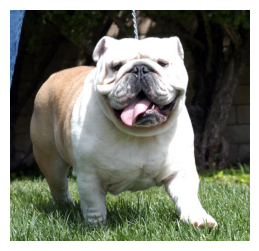

In [38]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("test_image.jpg")
plt.figure(figsize=(4, 3))
plt.imshow(img)
plt.axis("off")
plt.show()

In [29]:
import json

with open("test_image.jpg", "rb") as f:
    image_bytes = f.read()

response = endpoint.invoke(
    body=image_bytes,
    content_type="application/x-image",
)

result = json.loads(response.body.read().decode("utf-8"))
result

{'predictions': [{'class_index': 68, 'probability': 0.5768397450447083},
  {'class_index': 39, 'probability': 0.4050349295139313},
  {'class_index': 104, 'probability': 0.006507856771349907},
  {'class_index': 3, 'probability': 0.002721115481108427},
  {'class_index': 40, 'probability': 0.002633547643199563}]}

Model classified that image with class 67 (Finish spitz) with probability 0.68, while provided image is in fact Bulldog (class 39), which is in fact second guess of model. Our model was wrong.

### Batch Transform Job for test subset
Let's now use Batch Transform Job to classify all images from test dataset:

In [ ]:
transformer = model_builder.transformer(
    instance_count=1,
    instance_type="ml.m5.xlarge",
    output_path=f"s3://{bucket}/test-predictions/",
    accept="application/json",
    assemble_with="Line"
)

transformer.transform(
    data=f"s3://{bucket}/dataset/test/",
    content_type="application/x-image",
    split_type="None"
)

transformer.wait()

INFO:sagemaker:Creating transform job with name: resnet50-dog-breed-2026-11-11-18-09-09-733


Output()

Let's get them from S3 bucket:

In [45]:
os.environ["S3_BUCKET"] = bucket
!aws s3 cp s3://{bucket}/test-predictions/ test_predictions --recursive

download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00003.jpg.out to test_predictions/001.Affenpinscher/Affenpinscher_00003.jpg.out
download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00023.jpg.out to test_predictions/001.Affenpinscher/Affenpinscher_00023.jpg.out
download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00036.jpg.out to test_predictions/001.Affenpinscher/Affenpinscher_00036.jpg.out
download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00048.jpg.out to test_predictions/001.Affenpinscher/Affenpinscher_00048.jpg.out
download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00058.jpg.out to test_predictions/001.Affenpinscher/Affenpinscher_00058.jpg.out
download: s3://sagemaker-us-east-1-XXXXXXXXXXXX/test-predictions/001.Affenpinscher/Affenpinscher_00071.jpg.out to t

Let's try to build confusion matrix:

In [53]:
import numpy as np
import json

confusion_matrix = np.zeros((133, 133))

root_path = Path('test_predictions')
for folder_class in os.listdir(root_path):
    true_class_idx = int(folder_class.split('.')[0]) - 1
    
    for classification in os.listdir(root_path / folder_class):
        with open(root_path / folder_class / classification) as f:
            predicted_class = json.load(f)['predictions'][0]['class_index']
        confusion_matrix[true_class_idx, predicted_class] += 1
    

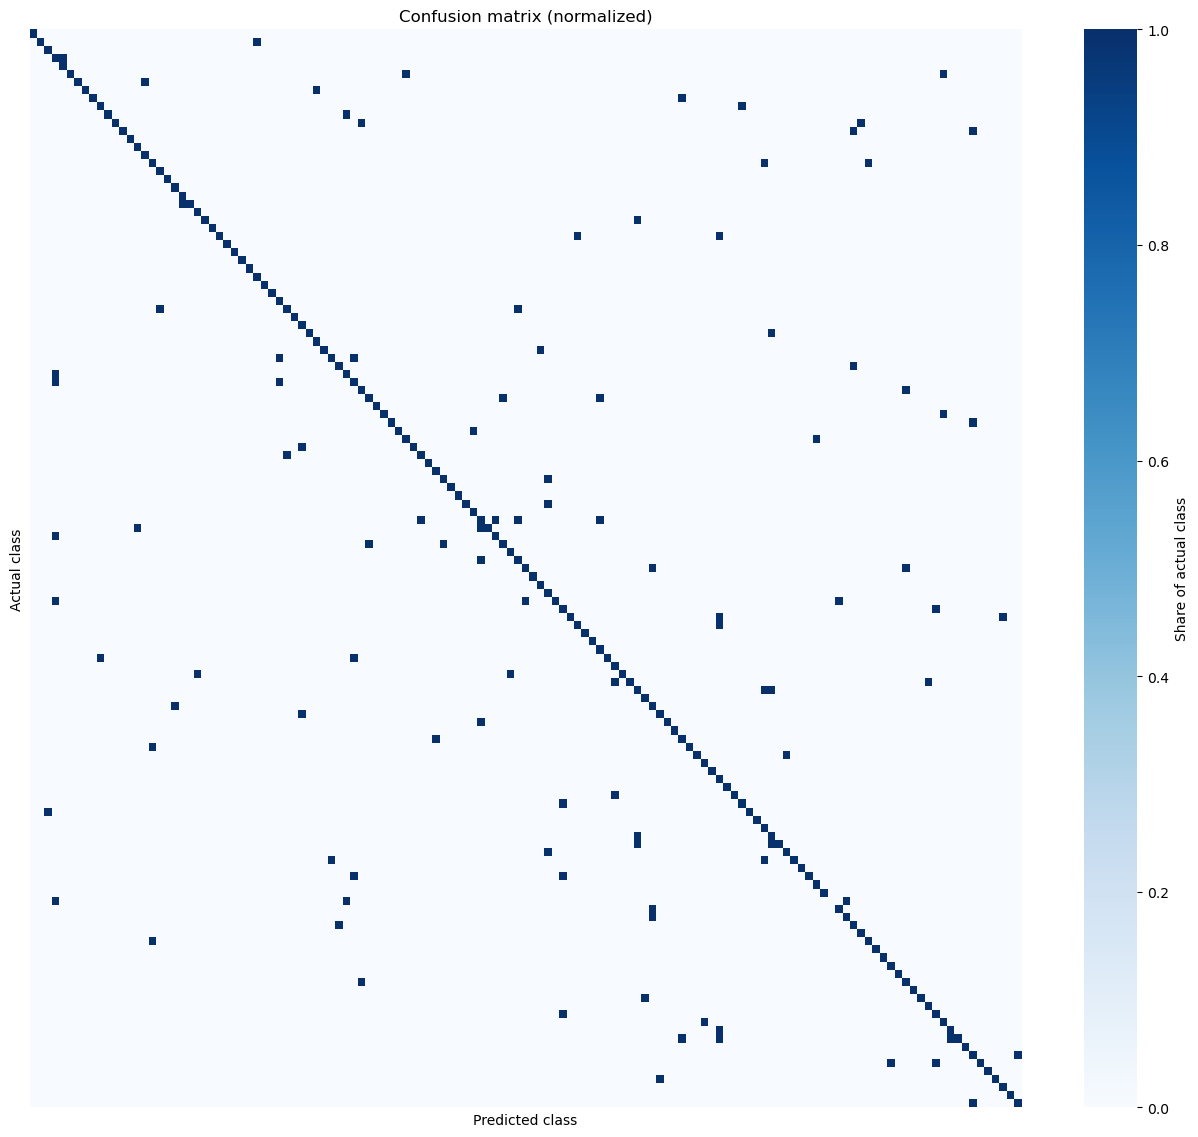

In [56]:
import seaborn as sns

plt.figure(figsize=(16, 14))
sns.heatmap(
    confusion_matrix, 
    cmap="Blues", 
    vmin=0, 
    vmax=1,
    xticklabels=False, 
    yticklabels=False,
    cbar_kws={"label": "Share of actual class"}
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion matrix (normalized)")
plt.show()

We can see that mostly points generate diagonal line, which is good, because predicated classes match true classes. However, there are cases when dogs are misclassified. For some classes we don't have singe correct classification.

That matrix is good starting point for further analysis that would allow to improve performance of this model.